# 02 — Investigate data quality before cleaning

## Goal
Decide which raw rows can support sales and customer analysis. We will measure missingness, inspect cancellations and unusual values, examine duplicate-looking rows, and check invoice consistency.

**Learning idea:** an unusual row is a question to investigate, not automatic permission to delete it. This lesson flags issues and preserves every original row. Cleaning comes next.

Source: Chen, D. (2015). [Online Retail, UCI](https://doi.org/10.24432/C5BW33), CC BY 4.0. Local input: `data/raw/Online Retail.xlsx`, sheet `Online Retail`. Prices are GBP. Raw grain: invoice line item; no guaranteed unique source line ID is supplied.

## Setup
Run cells from top to bottom using **E-commerce Analytics (.venv)**. All checks use the complete raw workbook, including anonymous sales, cancellations, and adjustments. Numeric flag percentages use **all raw rows** as their denominator unless another population is explicitly named.

We use a copy only for a whitespace/case sensitivity check; we do not overwrite the workbook or produce a cleaned dataset.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import display, Markdown, Image

current = Path.cwd().resolve()
PROJECT_ROOT = next(folder for folder in [current, *current.parents]
                    if (folder / 'scripts' / 'download_data.py').is_file())
DATA_FILE = PROJECT_ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
manifest = json.loads((DATA_FILE.parent / 'source_manifest.json').read_text(encoding='utf-8'))
source_hash = sha256(DATA_FILE.read_bytes()).hexdigest()
assert source_hash == manifest['sha256'], 'Source checksum changed.'

retail_raw = pd.read_excel(
    DATA_FILE, sheet_name='Online Retail', engine='openpyxl',
    dtype={'InvoiceNo': 'string', 'StockCode': 'string', 'CustomerID': 'string'},
)
assert retail_raw.shape == (541_909, 8)
assert retail_raw.columns.tolist() == [
    'InvoiceNo', 'StockCode', 'Description', 'Quantity',
    'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country',
]
assert pd.api.types.is_datetime64_any_dtype(retail_raw['InvoiceDate'])
original_frame_hash = int(pd.util.hash_pandas_object(retail_raw, index=True).sum())
row_count = len(retail_raw)
FIGURES = PROJECT_ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 10)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': '#242424', 'text.color': '#242424',
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
print(f'Loaded {row_count:,} invoice line items; no rows have been removed.')

Loaded 541,909 invoice line items; no rows have been removed.


## Steps
### 1. Measure missing values
`isna()` produces a table of true/false flags. Summing those flags counts missing cells. Dividing by the number of rows produces a missingness rate.

An absent customer ID prevents us from identifying that customer's purchase history. It does **not**, by itself, establish that the sale is invalid. The source page says no missing values; we check the actual file rather than relying on that metadata.

In [2]:
missing = pd.DataFrame({
    'Missing rows': retail_raw.isna().sum(),
    'Missing % of raw rows': retail_raw.isna().mean().mul(100),
})
display(missing.style.format({'Missing rows': '{:,.0f}', 'Missing % of raw rows': '{:.2f}%'}))

text_columns = ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Country']
blank_text = pd.Series({
    column: int(retail_raw[column].astype('string').str.strip().eq('').fillna(False).sum())
    for column in text_columns
}, name='Non-null blank/whitespace strings')
display(blank_text.to_frame())

,Missing rows,Missing % of raw rows
InvoiceNo,0,0.00%
StockCode,0,0.00%
Description,"1,454",0.27%
Quantity,0,0.00%
InvoiceDate,0,0.00%
UnitPrice,0,0.00%
CustomerID,"135,080",24.93%
Country,0,0.00%


,Non-null blank/whitespace strings
InvoiceNo,0
StockCode,0
Description,0
CustomerID,0
Country,0


### 2. Separate the flags from the cleaning rules
UCI documents invoice IDs starting with `C` as cancellations. Negative quantities can also describe adjustments; the sign alone does not prove a physical return.

These flags **overlap**. For example, a cancellation may also have a negative quantity and a missing customer ID. Never add the flag counts together to claim a count of bad rows.

In [3]:
cancelled = retail_raw['InvoiceNo'].str.upper().str.startswith('C', na=False)
duplicate_extra = retail_raw.duplicated(keep='first')
duplicate_members = retail_raw.duplicated(keep=False)
flags = pd.DataFrame({
    'Missing customer ID': retail_raw['CustomerID'].isna(),
    'Missing item description': retail_raw['Description'].isna(),
    'C-prefixed invoice': cancelled,
    'Negative quantity': retail_raw['Quantity'].lt(0),
    'Zero quantity': retail_raw['Quantity'].eq(0),
    'Negative unit price': retail_raw['UnitPrice'].lt(0),
    'Zero unit price': retail_raw['UnitPrice'].eq(0),
    'Exact duplicate beyond first': duplicate_extra,
})
flag_summary = pd.DataFrame({
    'Flagged rows': flags.sum().astype(int),
    '% of all raw rows': flags.mean().mul(100),
})
display(flag_summary.style.format({'Flagged rows': '{:,.0f}', '% of all raw rows': '{:.2f}%'}))
print(f'Rows matching at least one flag: {flags.any(axis=1).sum():,}; this is a review population, not a deletion list.')

,Flagged rows,% of all raw rows
Missing customer ID,"135,080",24.93%
Missing item description,"1,454",0.27%
C-prefixed invoice,"9,288",1.71%
Negative quantity,"10,624",1.96%
Zero quantity,0,0.00%
Negative unit price,2,0.00%
Zero unit price,"2,515",0.46%
Exact duplicate beyond first,"5,268",0.97%


Rows matching at least one flag: 149,217; this is a review population, not a deletion list.


### 3. Cross-check cancellation IDs against quantity signs
A cross-tab counts combinations. This tells us whether every negative quantity is attached to a cancellation ID, and whether every cancellation has a negative quantity.

Each row enters exactly one cell, so this table should sum to the workbook row count.

In [4]:
quantity_sign = pd.Series('Positive', index=retail_raw.index, name='Quantity sign')
quantity_sign.loc[retail_raw['Quantity'].lt(0)] = 'Negative'
quantity_sign.loc[retail_raw['Quantity'].eq(0)] = 'Zero'
quantity_sign.loc[retail_raw['Quantity'].isna()] = 'Missing'
invoice_type = cancelled.map({False: 'Other invoice ID', True: 'C-prefixed invoice'})
cancellation_crosscheck = pd.crosstab(invoice_type, quantity_sign).reindex(
    index=['Other invoice ID', 'C-prefixed invoice'],
    columns=['Negative', 'Zero', 'Positive', 'Missing'], fill_value=0,
)
display(cancellation_crosscheck)
assert int(cancellation_crosscheck.to_numpy().sum()) == row_count
non_cancel_negative = int((~cancelled & retail_raw['Quantity'].lt(0)).sum())
display(retail_raw.loc[~cancelled & retail_raw['Quantity'].lt(0)].head(6))

Quantity sign,Negative,Zero,Positive,Missing
InvoiceNo,,,,
Other invoice ID,1336,0,531285,0
C-prefixed invoice,9288,0,0,0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,<NA>,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,<NA>,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,<NA>,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,<NA>,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,<NA>,United Kingdom


### 4. Examine duplicate-looking rows
An invoice number repeats legitimately because an order contains multiple line items. Even `InvoiceNo + StockCode` is not a guaranteed line key.

We distinguish **extra exact copies beyond the first occurrence** from **all rows belonging to duplicate groups**. We also repeat the comparison after trimming whitespace and standardizing case in text columns, using a temporary copy. Neither count proves that deletion is correct.

In [5]:
normalized = retail_raw.copy()
for column in text_columns:
    normalized[column] = normalized[column].astype('string').str.strip().str.upper()
normalized_extra = int(normalized.duplicated().sum())
duplicate_overview = pd.Series({
    'Exact copies beyond first occurrence': int(duplicate_extra.sum()),
    'All rows belonging to exact duplicate groups': int(duplicate_members.sum()),
    'Copies beyond first after whitespace/case normalization': normalized_extra,
    'Rows repeating InvoiceNo + StockCode beyond first (not a unique key)':
        int(retail_raw.duplicated(['InvoiceNo', 'StockCode']).sum()),
}, name='Rows')
display(duplicate_overview.to_frame())
duplicate_sample = retail_raw.loc[duplicate_members].reset_index(names='Source row index')
display(duplicate_sample.sort_values(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice']).head(8))
del normalized

,Rows
Exact copies beyond first occurrence,5268
All rows belonging to exact duplicate groups,10147
Copies beyond first after whitespace/case normalization,5268
Rows repeating InvoiceNo + StockCode beyond first (not a unique key),10684


,Source row index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2,494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
3,517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
0,485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
7,539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
1,489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
5,527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
4,521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
6,537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom


### 5. Inspect numeric extremes and unusual item codes
Quantiles show the middle and tails without assuming a normal distribution. We inspect the largest absolute quantities and prices. Wholesale transactions can be large, so size alone is not an error rule.

The item-code format check below is only a **review heuristic**: five digits with up to two letter suffixes. Codes outside it may describe services, adjustments, or legitimate items. Their descriptions need review before product rankings are defined.

In [6]:
numeric_profile = retail_raw[['Quantity', 'UnitPrice']].quantile([0, .01, .5, .99, 1]).T
numeric_profile.columns = ['Minimum', '1st percentile', 'Median', '99th percentile', 'Maximum']
display(numeric_profile.style.format('{:,.2f}'))

extreme_indices = retail_raw['Quantity'].abs().nlargest(4).index.union(
    retail_raw['UnitPrice'].abs().nlargest(4).index, sort=False,
)
display(retail_raw.loc[extreme_indices].reset_index(names='Source row index'))

format_review = ~retail_raw['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]{0,2}', na=False)
review_codes = (retail_raw.loc[format_review]
                .groupby('StockCode', dropna=False)
                .agg(Rows=('InvoiceNo', 'size'), Example_description=('Description', 'first'))
                .sort_values('Rows', ascending=False))
display(review_codes.head(20))
print(f'{int(format_review.sum()):,} rows match the item-code review heuristic; none are automatically excluded.')

,Minimum,1st percentile,Median,99th percentile,Maximum
Quantity,"-80,995.00",-2.00,3.00,100.00,"80,995.00"
UnitPrice,"-11,062.06",0.19,2.08,18.00,"38,970.00"


,Source row index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom
1,540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom
2,61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
3,61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom
4,222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098,United Kingdom
5,524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,<NA>,United Kingdom
6,43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,<NA>,United Kingdom
7,43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,<NA>,United Kingdom


,Rows,Example_description
StockCode,,
POST,1256,POSTAGE
DOT,710,DOTCOM POSTAGE
M,571,Manual
C2,144,CARRIAGE
D,77,Discount
S,63,SAMPLES
BANK CHARGES,37,Bank Charges
AMAZONFEE,34,AMAZON FEE
CRUK,16,CRUK Commission


2,995 rows match the item-code review heuristic; none are automatically excluded.


### 6. Check whether invoice attributes agree across lines
Before creating an order table in SQLite, we need to know whether one invoice maps to multiple known customers, countries, or timestamps. Missing IDs are counted separately; we do not invent an identity or fill IDs from neighboring rows.

These are investigation flags, not constraints declared safe for the raw source.

In [7]:
invoice_profile = retail_raw.groupby('InvoiceNo', dropna=False).agg(
    Lines=('StockCode', 'size'),
    Known_customers=('CustomerID', 'nunique'),
    Countries=('Country', 'nunique'),
    Timestamps=('InvoiceDate', 'nunique'),
)
invoice_checks = pd.Series({
    'Invoice IDs with more than one known customer': int(invoice_profile['Known_customers'].gt(1).sum()),
    'Invoice IDs with more than one country': int(invoice_profile['Countries'].gt(1).sum()),
    'Invoice IDs with more than one timestamp': int(invoice_profile['Timestamps'].gt(1).sum()),
}, name='Invoice ID groups')
display(invoice_checks.to_frame())
inconsistent = invoice_profile[['Known_customers', 'Countries', 'Timestamps']].gt(1).any(axis=1)
display(invoice_profile.loc[inconsistent].head(8))

,Invoice ID groups
Invoice IDs with more than one known customer,0
Invoice IDs with more than one country,0
Invoice IDs with more than one timestamp,43


,Lines,Known_customers,Countries,Timestamps
InvoiceNo,,,,
536591,40,1,1,2
540185,29,1,1,2
541596,103,1,1,2
541631,72,1,1,2
541809,91,0,1,2
541816,73,1,1,2
541849,49,1,1,2
542217,18,1,1,2


### 7. Inspect missing customer IDs over time
The same overall missingness rate can hide variation between months. We show the missing-ID share alongside raw row volume so the denominator stays visible.

December 2011 ends on the source's last observed date, not at month end. Its smaller volume must not be interpreted as a full-month decline. Dates have no documented timezone. Closed days or gaps are not evidence of an ingestion failure in this historical extract.

,Raw_rows,Missing_customer_rows,C_prefixed_rows,Duplicate_extra_rows,Missing_customer_pct,First_observed_timestamp,Last_observed_timestamp
Month,,,,,,,
2010-12,42481,15631,728,500,36.80%,2010-12-01 08:26:00,2010-12-23 17:41:00
2011-01,35147,13235,701,247,37.66%,2011-01-04 10:00:00,2011-01-31 16:59:00
2011-02,27707,7344,475,228,26.51%,2011-02-01 08:23:00,2011-02-28 17:04:00
2011-03,36748,8926,699,309,24.29%,2011-03-01 08:30:00,2011-03-31 19:55:00
2011-04,29916,6718,559,215,22.46%,2011-04-01 08:22:00,2011-04-28 19:53:00
2011-05,37030,8122,621,248,21.93%,2011-05-01 10:51:00,2011-05-31 15:53:00
2011-06,36874,9038,711,265,24.51%,2011-06-01 07:37:00,2011-06-30 20:08:00
2011-07,39518,12016,685,251,30.41%,2011-07-01 08:16:00,2011-07-31 16:04:00
2011-08,35284,7622,668,220,21.60%,2011-08-01 08:30:00,2011-08-31 17:45:00


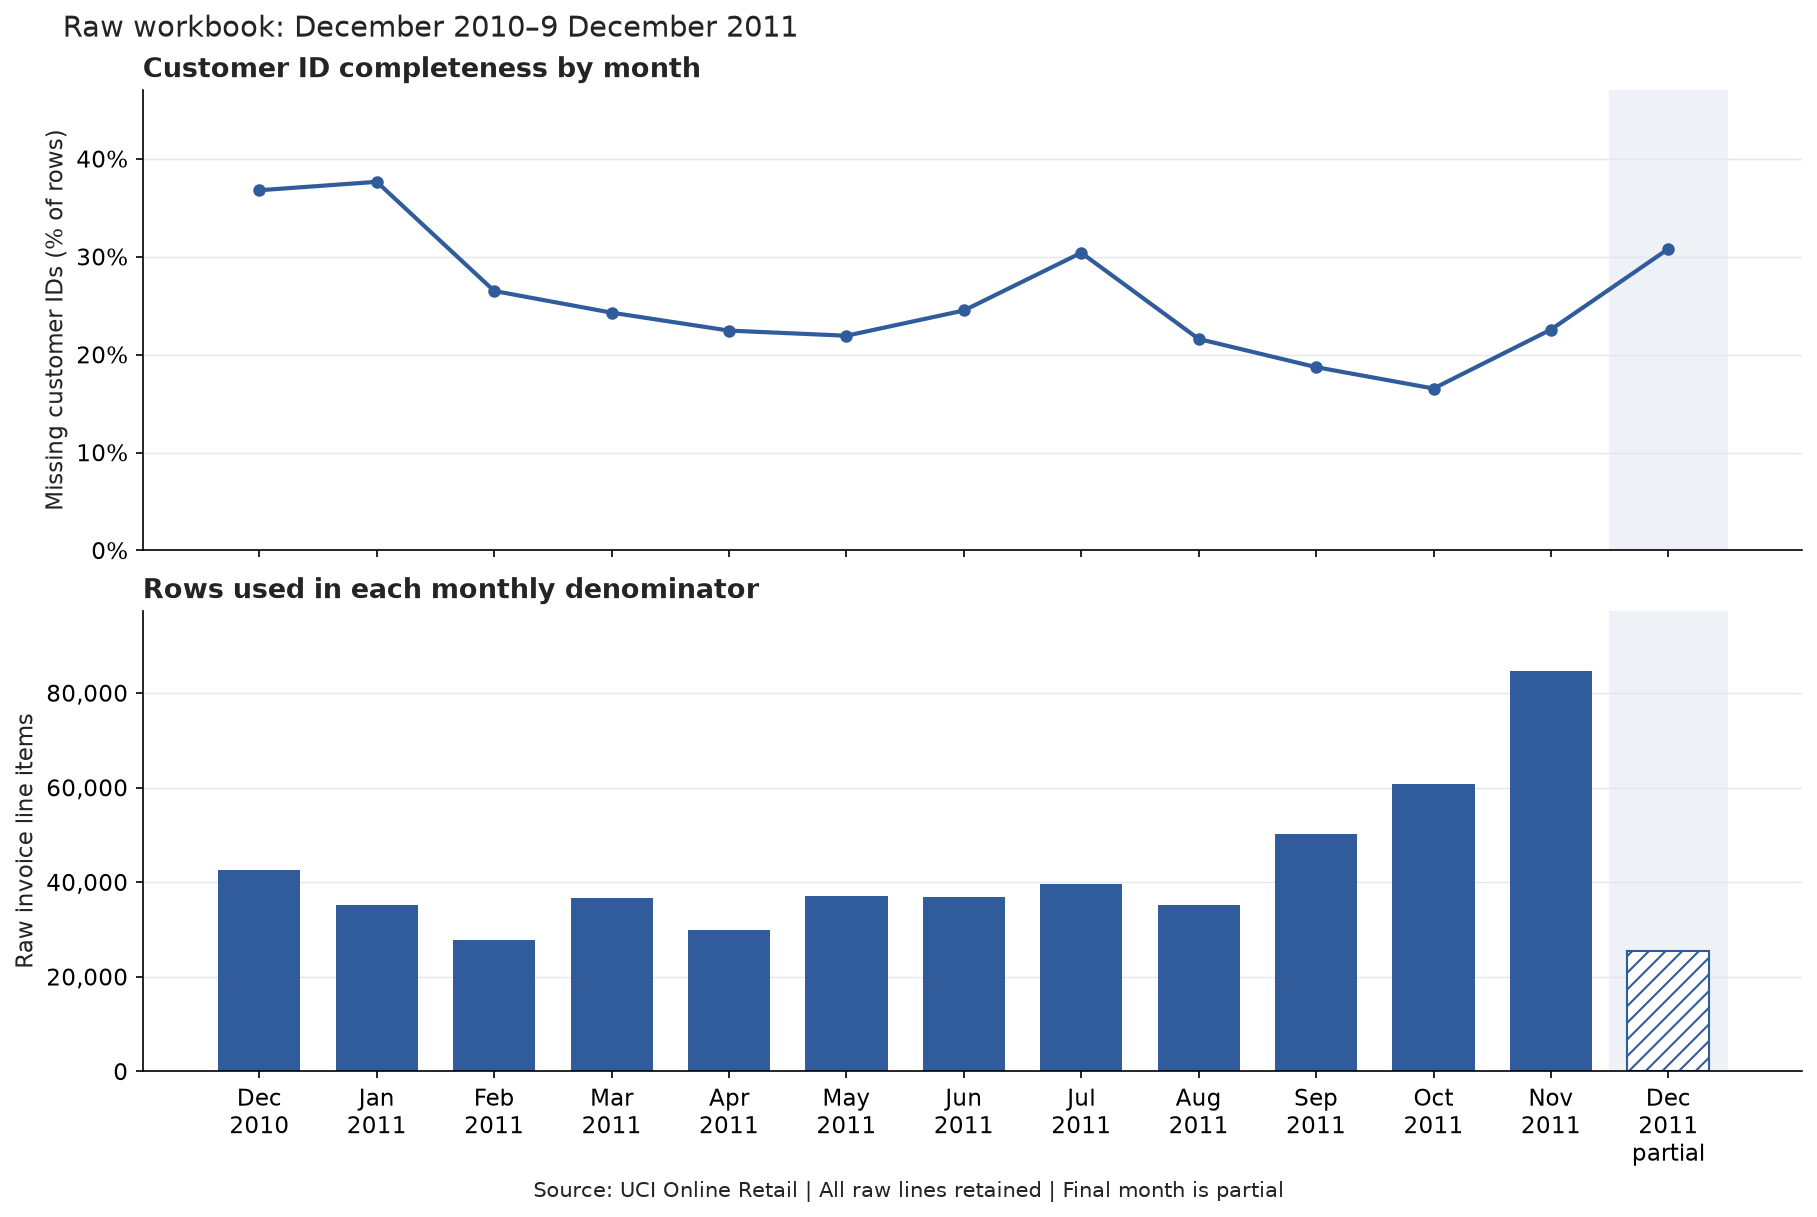

In [8]:
month = retail_raw['InvoiceDate'].dt.to_period('M').astype(str)
monthly_quality = flags.assign(Month=month).groupby('Month').agg(
    Raw_rows=('Missing customer ID', 'size'),
    Missing_customer_rows=('Missing customer ID', 'sum'),
    C_prefixed_rows=('C-prefixed invoice', 'sum'),
    Duplicate_extra_rows=('Exact duplicate beyond first', 'sum'),
)
monthly_quality['Missing_customer_pct'] = (
    monthly_quality['Missing_customer_rows'] / monthly_quality['Raw_rows'] * 100
)
observed_dates = retail_raw.assign(Month=month).groupby('Month')['InvoiceDate'].agg(['min', 'max'])
monthly_quality = monthly_quality.join(observed_dates.rename(columns={
    'min': 'First_observed_timestamp', 'max': 'Last_observed_timestamp',
}))
display(monthly_quality.style.format({'Missing_customer_pct': '{:.2f}%'}))

labels = pd.to_datetime(monthly_quality.index).strftime('%b\n%Y').tolist()
last_month = retail_raw['InvoiceDate'].max().strftime('%Y-%m')
labels[-1] += '\npartial'
positions = list(range(len(labels)))
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, layout='constrained')
axes[0].plot(positions, monthly_quality['Missing_customer_pct'], color='#315C9B',
             marker='o', linewidth=2, markersize=5)
axes[0].set_ylabel('Missing customer IDs (% of rows)')
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
axes[0].set_ylim(0, max(35, monthly_quality['Missing_customer_pct'].max() * 1.25))
axes[0].set_title('Customer ID completeness by month', loc='left', fontweight='bold')
bars = axes[1].bar(positions, monthly_quality['Raw_rows'], color='#315C9B', width=.7)
bars[-1].set_facecolor('white')
bars[-1].set_edgecolor('#315C9B')
bars[-1].set_hatch('///')
axes[1].set_ylabel('Raw invoice line items')
axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].set_ylim(0, monthly_quality['Raw_rows'].max() * 1.15)
axes[1].set_title('Rows used in each monthly denominator', loc='left', fontweight='bold')
axes[1].set_xticks(positions, labels)
for axis in axes:
    axis.set_axisbelow(True)
    axis.grid(axis='y', color='#E4E7EB', linewidth=.7)
    axis.axvspan(len(labels) - 1.5, len(labels) - .5, color='#EEF1F5', zorder=0)
fig.suptitle('Raw workbook: December 2010–9 December 2011', x=.03, ha='left', fontsize=14)
fig.supxlabel('Source: UCI Online Retail | All raw lines retained | Final month is partial', fontsize=10)
figure_path = FIGURES / '02_customer_id_completeness.png'
fig.savefig(figure_path, dpi=150, bbox_inches='tight')
display(Image(filename=str(figure_path)))
plt.close(fig)

## Checks
### 8. Reconcile totals and preserve the source
We reconcile monthly counts to the complete file and repeat two important counts with Python iteration rather than pandas aggregation. We also verify that the original DataFrame and workbook fingerprint have not changed.

These checks confirm the profiling calculations and source preservation. They do not prove that every source row is a genuine commercial transaction.

In [9]:
assert int(monthly_quality['Raw_rows'].sum()) == row_count
assert int(monthly_quality['Missing_customer_rows'].sum()) == int(flags['Missing customer ID'].sum())
assert int(monthly_quality['C_prefixed_rows'].sum()) == int(cancelled.sum())
assert int(monthly_quality['Duplicate_extra_rows'].sum()) == int(duplicate_extra.sum())
assert sum(pd.isna(value) for value in retail_raw['CustomerID'].array) == int(flags['Missing customer ID'].sum())
assert sum(str(value).upper().startswith('C') for value in retail_raw['InvoiceNo'].array) == int(cancelled.sum())
assert int(duplicate_members.sum()) >= int(duplicate_extra.sum())
assert int(pd.util.hash_pandas_object(retail_raw, index=True).sum()) == original_frame_hash
assert sha256(DATA_FILE.read_bytes()).hexdigest() == source_hash
assert retail_raw.shape == (541_909, 8)
print('All reconciliations passed. The raw workbook and all source rows are unchanged.')

All reconciliations passed. The raw workbook and all source rows are unchanged.


## Next Steps
### 9. Read the findings and choose the right population
The notes below separate observations from proposed treatment. Counts come from the executed cells above; confidence in a count does not establish its business cause.

We save a compact evidence summary for the next lesson. It contains quality counts, not a cleaned transaction dataset.

In [10]:
missing_customers = int(flags['Missing customer ID'].sum())
missing_pct = missing_customers / row_count * 100
negative_qty = int(flags['Negative quantity'].sum())
zero_price = int(flags['Zero unit price'].sum())
negative_price = int(flags['Negative unit price'].sum())
dupes = int(duplicate_extra.sum())
unknown_customer_invoices = int(invoice_profile['Known_customers'].eq(0).sum())

notes = f"""# Stage 2 — Data quality findings

Source: Chen, D. (2015), [UCI Online Retail](https://doi.org/10.24432/C5BW33), CC BY 4.0. Workbook: `data/raw/Online Retail.xlsx`, sheet `Online Retail`. SHA-256: `{source_hash}`.

Scope: {row_count:,} original invoice line items, eight columns, {retail_raw['InvoiceDate'].min():%d %B %Y}–{retail_raw['InvoiceDate'].max():%d %B %Y}. Prices are GBP. No source rows were deleted or changed. Evidence and code: `notebooks/02_data_quality.ipynb`.

| Observation | Risk and proposed treatment | Priority / evidence confidence |
| --- | --- | --- |
| {missing_customers:,} missing customer IDs ({missing_pct:.2f}% of all raw rows); {unknown_customer_invoices:,} raw invoice groups have no known customer | High risk for customer history. Retain otherwise eligible anonymous sales for sales analysis; use known IDs for customer analysis and disclose coverage. Never group all missing IDs into one customer. Cause is not established. | High / high for counts |
| {int(cancelled.sum()):,} C-prefixed rows; {negative_qty:,} negative-quantity rows, including {non_cancel_negative:,} without a C prefix | Separate cancellation/credit entries from purchases and other adjustments. A negative quantity alone does not establish a physical return. | High / high for counts; business causes unresolved |
| {zero_price:,} zero-price rows and {negative_price:,} negative-price rows | Review descriptions and item codes before setting purchase eligibility. Do not silently include adjustments in average order value. | High / high for counts |
| {dupes:,} exact copies beyond the first ({dupes / row_count * 100:.2f}%); {int(duplicate_members.sum()):,} total rows in exact duplicate groups | Deletion could remove legitimate repeated lines; retention could overstate value if they are duplicated records. Preserve them pending an explicit baseline and sensitivity comparison. No true line identifier is supplied. | Medium / high for equality, unresolved for cause |
| {normalized_extra:,} copies beyond first after whitespace/case normalization | Cosmetic normalization is not sufficient evidence that a row is duplicated. Raw strings remain unchanged. | Medium / high |
| Invoice IDs with multiple known customers: {int(invoice_checks.iloc[0]):,}; multiple countries: {int(invoice_checks.iloc[1]):,}; multiple timestamps: {int(invoice_checks.iloc[2]):,} | Review these groups before imposing one-to-one invoice dimension rules in SQLite. Do not infer that an invoice uniquely identifies a customer or timestamp without a rule. | Medium / high for counts |
| Item-code heuristic flags {int(format_review.sum()):,} rows | Review candidate service/adjustment codes before calling the product ranking merchandise revenue. Format alone is not an invalidity rule. | Medium / high for flag, unresolved for classification |
| December 2011 ends on {retail_raw['InvoiceDate'].max():%d %B}, not month end | Mark this month partial. Exclude it from full-month comparisons or compare matching date windows. | High / high |

## Temporal and coverage notes

The chart and monthly table show missing-customer shares together with raw row denominators. Variation does not establish an ingestion failure or its cause. This is a static historical extract, so a modern freshness SLA does not apply. Missing IDs constrain observable customer coverage; date gaps may reflect trading patterns. There is no documented ingestion timestamp or timezone.

## Checks completed

Source checksum and expected schema/shape; nulls and blank text; overlapping review flags; cancellation-by-quantity cross-tab; exact and normalized duplicate comparisons; numeric quantiles and extreme samples; item-code review candidates; invoice consistency; monthly completeness and volume; count reconciliations and independent Python recounts for missing customer IDs and C prefixes; unchanged source/DataFrame checks.

## Next lesson: construct documented analysis populations

1. Define positive purchase lines, cancellation/credit entries, and other adjustments, retaining source row lineage.
2. Keep anonymous eligible purchases for overall sales; restrict customer history to known IDs.
3. Decide a duplicate baseline and calculate a with/without-exact-copy sensitivity, rather than asserting an unproven source error.
4. Review the item-code candidates before defining merchandise rankings.
5. Record order eligibility, average order value, and revenue definitions before aggregation. Net recorded line value is not profit.

No cleaned transaction dataset, finalized business KPI, RFM segmentation, or causal explanation is produced in this lesson.
"""
(PROJECT_ROOT / 'docs' / 'stage_02_notes.md').write_text(notes, encoding='utf-8')
summary = {
    'source_sha256': source_hash, 'raw_rows': row_count,
    'flags': {name: int(value) for name, value in flags.sum().items()},
    'normalized_duplicate_extra_rows': normalized_extra,
    'duplicate_group_member_rows': int(duplicate_members.sum()),
    'negative_quantity_without_c_prefix_rows': non_cancel_negative,
    'invoice_consistency_flags': {name: int(value) for name, value in invoice_checks.items()},
    'source_modified': False,
}
processed = PROJECT_ROOT / 'data' / 'processed'
processed.mkdir(parents=True, exist_ok=True)
(processed / 'quality_summary.json').write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
monthly_quality.to_csv(processed / 'monthly_quality.csv', index=True)
display(Markdown(notes))

# Stage 2 — Data quality findings

Source: Chen, D. (2015), [UCI Online Retail](https://doi.org/10.24432/C5BW33), CC BY 4.0. Workbook: `data/raw/Online Retail.xlsx`, sheet `Online Retail`. SHA-256: `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d`.

Scope: 541,909 original invoice line items, eight columns, 01 December 2010–09 December 2011. Prices are GBP. No source rows were deleted or changed. Evidence and code: `notebooks/02_data_quality.ipynb`.

| Observation | Risk and proposed treatment | Priority / evidence confidence |
| --- | --- | --- |
| 135,080 missing customer IDs (24.93% of all raw rows); 3,710 raw invoice groups have no known customer | High risk for customer history. Retain otherwise eligible anonymous sales for sales analysis; use known IDs for customer analysis and disclose coverage. Never group all missing IDs into one customer. Cause is not established. | High / high for counts |
| 9,288 C-prefixed rows; 10,624 negative-quantity rows, including 1,336 without a C prefix | Separate cancellation/credit entries from purchases and other adjustments. A negative quantity alone does not establish a physical return. | High / high for counts; business causes unresolved |
| 2,515 zero-price rows and 2 negative-price rows | Review descriptions and item codes before setting purchase eligibility. Do not silently include adjustments in average order value. | High / high for counts |
| 5,268 exact copies beyond the first (0.97%); 10,147 total rows in exact duplicate groups | Deletion could remove legitimate repeated lines; retention could overstate value if they are duplicated records. Preserve them pending an explicit baseline and sensitivity comparison. No true line identifier is supplied. | Medium / high for equality, unresolved for cause |
| 5,268 copies beyond first after whitespace/case normalization | Cosmetic normalization is not sufficient evidence that a row is duplicated. Raw strings remain unchanged. | Medium / high |
| Invoice IDs with multiple known customers: 0; multiple countries: 0; multiple timestamps: 43 | Review these groups before imposing one-to-one invoice dimension rules in SQLite. Do not infer that an invoice uniquely identifies a customer or timestamp without a rule. | Medium / high for counts |
| Item-code heuristic flags 2,995 rows | Review candidate service/adjustment codes before calling the product ranking merchandise revenue. Format alone is not an invalidity rule. | Medium / high for flag, unresolved for classification |
| December 2011 ends on 09 December, not month end | Mark this month partial. Exclude it from full-month comparisons or compare matching date windows. | High / high |

## Temporal and coverage notes

The chart and monthly table show missing-customer shares together with raw row denominators. Variation does not establish an ingestion failure or its cause. This is a static historical extract, so a modern freshness SLA does not apply. Missing IDs constrain observable customer coverage; date gaps may reflect trading patterns. There is no documented ingestion timestamp or timezone.

## Checks completed

Source checksum and expected schema/shape; nulls and blank text; overlapping review flags; cancellation-by-quantity cross-tab; exact and normalized duplicate comparisons; numeric quantiles and extreme samples; item-code review candidates; invoice consistency; monthly completeness and volume; count reconciliations and independent Python recounts for missing customer IDs and C prefixes; unchanged source/DataFrame checks.

## Next lesson: construct documented analysis populations

1. Define positive purchase lines, cancellation/credit entries, and other adjustments, retaining source row lineage.
2. Keep anonymous eligible purchases for overall sales; restrict customer history to known IDs.
3. Decide a duplicate baseline and calculate a with/without-exact-copy sensitivity, rather than asserting an unproven source error.
4. Review the item-code candidates before defining merchandise rankings.
5. Record order eligibility, average order value, and revenue definitions before aggregation. Net recorded line value is not profit.

No cleaned transaction dataset, finalized business KPI, RFM segmentation, or causal explanation is produced in this lesson.


### Your checkpoint
A row has a positive quantity, a positive price, and no customer ID. Should we remove it from **all sales analysis**, or keep it for sales while excluding it from **customer purchase history**? Explain why.

Then look at the cancellation cross-tab: why would filtering only invoice IDs beginning with `C` leave some negative quantities behind?

When you're ready, we will turn these observations into explicit cleaning rules and compare the retained populations.